# E.1 Paint an admixed chromosome

We observe alleles along one chromosome copy, but not the source population of each segment. Recombination makes ancestry persist across neighboring markers and occasionally switch. The alleles are imperfect evidence because both sources can carry the same allele.

Let $Z_\ell\in\{1,2\}$ be hidden local ancestry and $H_\ell\in\{0,1\}$ the observed allele. With genome-wide source fractions $q_k$, genetic distance $r_\ell$, and $t$ generations since mixing, use

$$P(Z_1=k)=q_k,\quad P(Z_{\ell+1}=k'\mid Z_\ell=k)=s_\ell 1_{k'=k}+(1-s_\ell)q_{k'},\quad s_\ell=e^{-r_\ell t}.$$

If source $k$ has allele frequency $p_{\ell k}$, then $H_\ell\mid Z_\ell=k\sim\operatorname{Bernoulli}(p_{\ell k})$. These are the hidden state, transition, and emission of an HMM.


## Twelve observed alleles

Suppose the observed alleles are mostly 1 on the left and 0 on the right. At each marker, allele 1 has frequency 0.8 in source 1 and 0.2 in source 2. A lone mismatch need not change the inferred ancestry; several neighboring alleles can. We expect posterior source-1 probability to be higher on the left.


In [1]:
library(hpgR)

allele <- c(1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0)
q <- c(0.5, 0.5)
source_frequency <- c(0.8, 0.2)
r <- 0.01
t <- 8
same_parental_tract <- exp(-r * t)
transition <- copyingTransition(same_parental_tract, q)
emission <- cbind(1 - source_frequency, source_frequency)
stopifnot(all(abs(rowSums(transition) - 1) < 1e-12))
stopifnot(all(abs(rowSums(emission) - 1) < 1e-12))

Forward probabilities summarize evidence from the left. Backward probabilities summarize evidence from the right. Their product, normalized at each marker, gives posterior ancestry probabilities.


In [2]:
markers <- length(allele)
fit <- hmmPosterior(t(emission[, allele + 1, drop = FALSE]), transition, q)
posterior <- unname(fit$posterior)
stopifnot(all(abs(rowSums(posterior) - 1) < 1e-12))
stopifnot(mean(posterior[1:5, 1]) > mean(posterior[8:12, 1]))


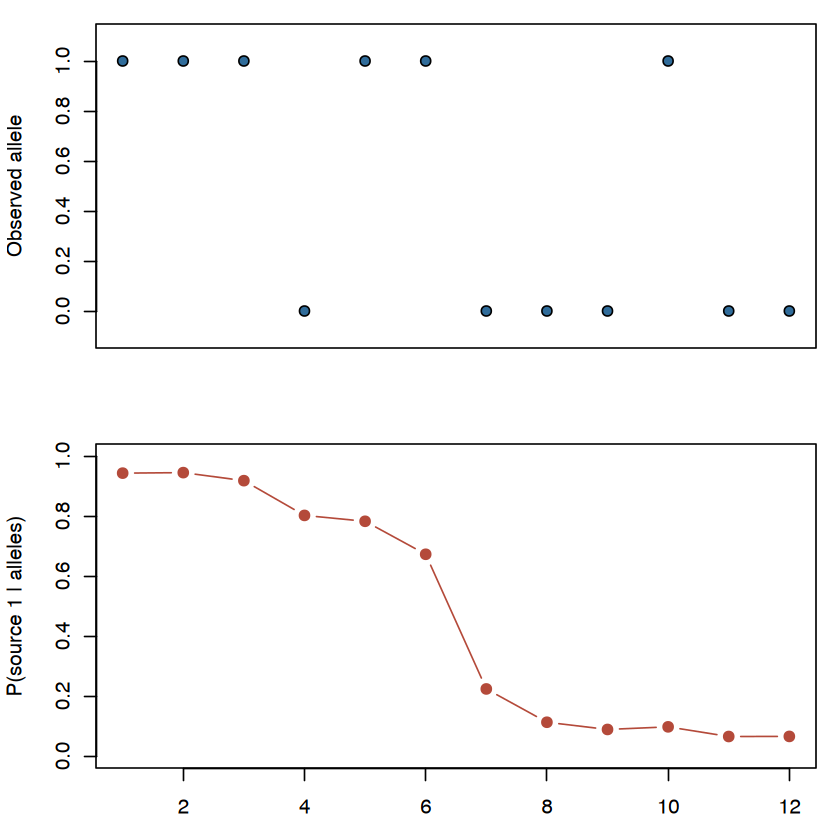

In [3]:
old_par <- par(mfrow = c(2, 1), mar = c(3, 4, 1, 1))
plot(seq_len(markers), allele, pch = 21, bg = '#306C9A', ylim = c(-0.1, 1.1),
     xlab = '', ylab = 'Observed allele', xaxt = 'n')
plot(seq_len(markers), posterior[, 1], type = 'b', pch = 19,
     col = '#B44A3A', ylim = c(0, 1), xlab = 'Marker',
     ylab = 'P(source 1 | alleles)')
par(old_par)

## Why tract lengths carry time information

The transition persists with $e^{-rt}$. Older mixing gives recombination more opportunities between markers. A recombination can redraw the same source, so an ancestry-color switch is less frequent than a recombination event. With $q_1=q_2=0.5$, the switch probability between these markers is $(1-e^{-rt})/2$.


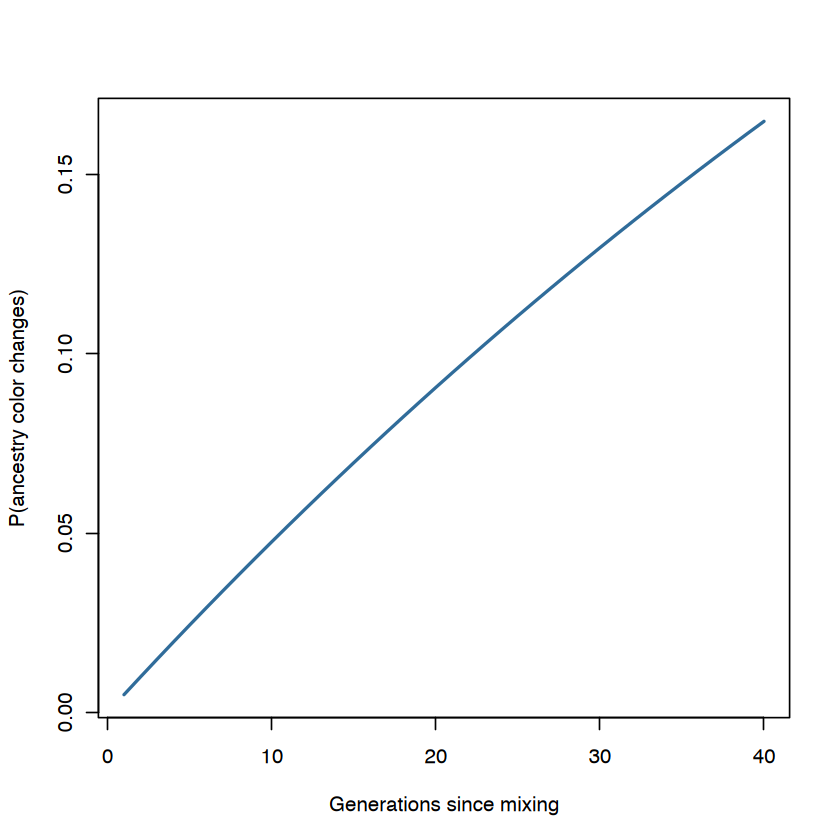

In [4]:
generations_since_mixing <- 1:40
switch_probability <- (1 - exp(-r * generations_since_mixing)) *
  (1 - sum(q^2))
plot(generations_since_mixing, switch_probability, type = 'l', lwd = 2,
     col = '#306C9A', xlab = 'Generations since mixing',
     ylab = 'P(ancestry color changes)')
stopifnot(all(diff(switch_probability) > 0))

## What to remember

Neighboring alleles and ancestry persistence jointly identify local ancestry. The posterior keeps uncertainty visible. Tract lengths inform the time since mixing under a specified recombination and admixture model; one colored chromosome is not a precise clock.

**Sources.** Pritchard, *An Owner's Guide to the Human Genome*, Section 3.2, chromosome-painting model and Eqs. 3.11–3.15. The twelve observed alleles, constant source frequencies, and $t=8$ are original teaching values; the transition and emission follow the lecture model.
